In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

df = pd.read_csv('evaluated_result.csv')

# coerce LLM score columns to numeric (turns 'skipped (generation error)' → NaN)
for col in ['llm_accuracy', 'llm_coherence', 'llm_language']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# flag error rows
df['is_error'] = df['generated_abstract'].astype(str).str.startswith('ERROR:')

# ── group num_of_neighbors into bins of 5 (1-5, 6-10, 11-15, …) ──────────────
BIN_SIZE = 5
max_neighbors = int(df['num_of_neighbors'].max())
bin_edges = list(range(0, max_neighbors + BIN_SIZE, BIN_SIZE))
NEIGHBOR_GROUPS = [f'{lo + 1}-{lo + BIN_SIZE}' for lo in bin_edges[:-1]]
df['neighbor_group'] = pd.cut(
    df['num_of_neighbors'], bins=bin_edges, labels=NEIGHBOR_GROUPS, right=True
)

def weighted_group_mean(frame: pd.DataFrame, value_col: str) -> pd.Series:
    """Mean of value_col per neighbour_group, weighted by num_of_neighbors."""
    def _wavg(g):
        mask = g[value_col].notna()
        if not mask.any():
            return np.nan
        return np.average(g.loc[mask, value_col], weights=g.loc[mask, 'num_of_neighbors'])
    return frame.groupby('neighbor_group', observed=True)[[value_col, 'num_of_neighbors']].apply(_wavg).reindex(NEIGHBOR_GROUPS)

print(f'{len(df)} rows  |  {df["is_error"].sum()} generation errors')
df.head(3)


945 rows  |  0 generation errors


,node_id,mag_id,original_abstract,generated_abstract,rouge1_f,rouge2_f,rougeL_f,bertscore_p,bertscore_r,bertscore_f1,llm_accuracy,llm_coherence,llm_language,num_of_neighbors,is_error,neighbor_group
0,1089,2953793718,We deal with the \textit{selective classificat...,"In this paper, we propose a novel approach to ...",0.3810,0.0895,0.1968,0.8708,0.8167,0.8429,NaN,NaN,NaN,69,False,66-70
1,1102,2958885478,Traditional 3D Convolutional Neural Networks (...,We propose a novel approach to the problem of ...,0.2338,0.0805,0.1538,0.8705,0.8034,0.8356,NaN,NaN,NaN,50,False,46-50
2,1121,2964693852,Various formal languages have been proposed in...,We consider the problem of computing the minim...,0.2442,0.0235,0.1279,0.8204,0.8270,0.8237,NaN,NaN,NaN,37,False,36-40


In [2]:
# ── shared plot style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
})

def bar_plot(series: pd.Series, title: str, ylabel: str,
             color: str, ylim=None, int_yaxis=False):
    """Bar chart with one bar per neighbour-count group (e.g. 1-5, 6-10, …)."""
    values = [series.get(g, np.nan) for g in NEIGHBOR_GROUPS]
    x = np.arange(len(NEIGHBOR_GROUPS))

    fig, ax = plt.subplots(figsize=(11, 4))
    bars = ax.bar(x, values, color=color, edgecolor='white', linewidth=0.6)

    # label bars that have data
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            label = f'{int(v)}' if int_yaxis else f'{v:.3f}'
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004 * (bar.get_height() or 1),
                    label, ha='center', va='bottom', fontsize=7)

    ax.set_xticks(x)
    ax.set_xticklabels(NEIGHBOR_GROUPS, rotation=45, ha='right')
    ax.set_xlabel('Number of neighbours', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    if int_yaxis:
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()


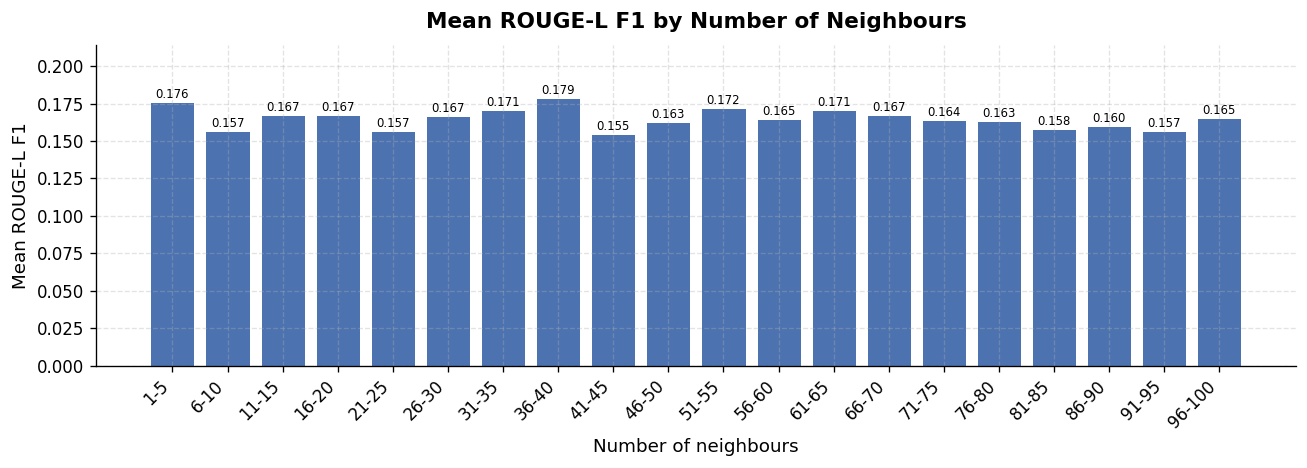

In [3]:
# ── 1. Mean ROUGE-L F1 ────────────────────────────────────────────────────────
rougel_mean = weighted_group_mean(df, 'rougeL_f')
bar_plot(rougel_mean,
         title='Mean ROUGE-L F1 by Number of Neighbours',
         ylabel='Mean ROUGE-L F1',
         color='#4C72B0',
         ylim=(0, max(rougel_mean.dropna()) * 1.2))

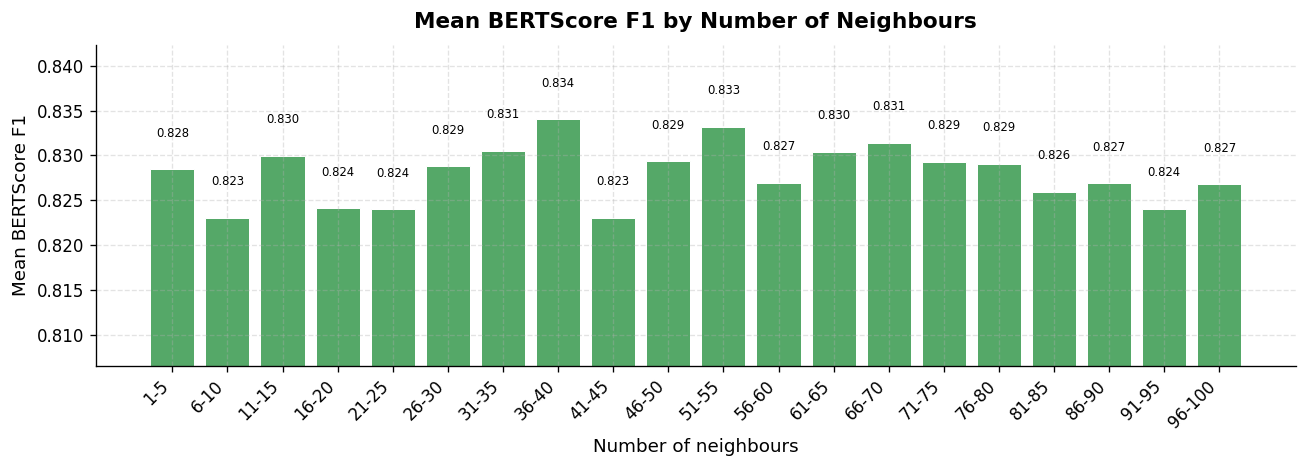

In [4]:
# ── 2. Mean BERTScore F1 ──────────────────────────────────────────────────────
bert_mean = weighted_group_mean(df, 'bertscore_f1')
ymin = bert_mean.dropna().min() * 0.98
ymax = bert_mean.dropna().max() * 1.01
bar_plot(bert_mean,
         title='Mean BERTScore F1 by Number of Neighbours',
         ylabel='Mean BERTScore F1',
         color='#55A868',
         ylim=(ymin, ymax))

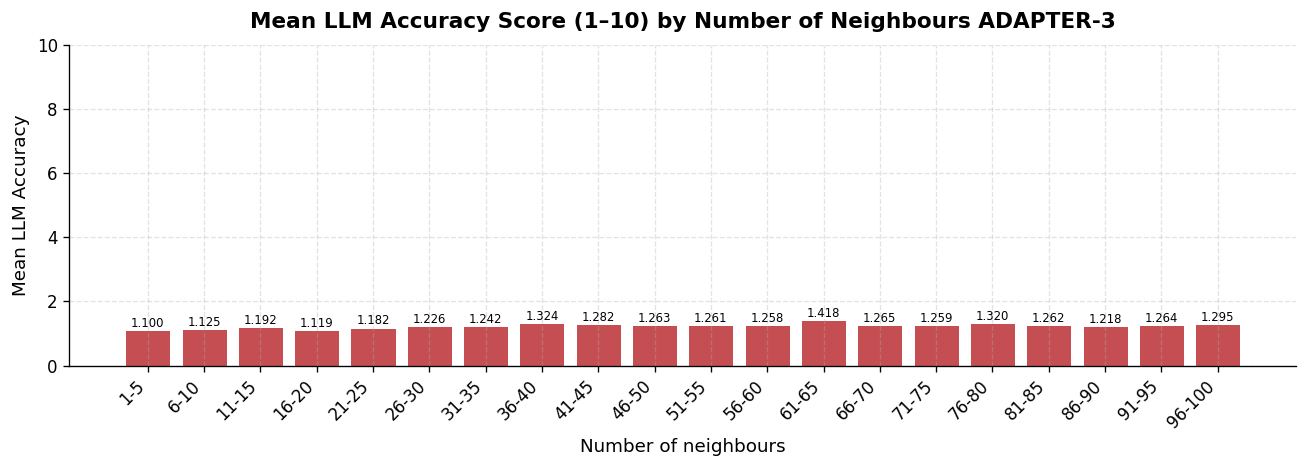

1.248936170212766
1.0


In [5]:
# ── 3. Mean LLM Accuracy ──────────────────────────────────────────────────────
acc_mean = weighted_group_mean(df, 'llm_accuracy')
bar_plot(acc_mean,
         title='Mean LLM Accuracy Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Accuracy',
         color='#C44E52',
         ylim=(0, 10))

print(df['llm_accuracy'].mean())
print(df['llm_accuracy'].median())

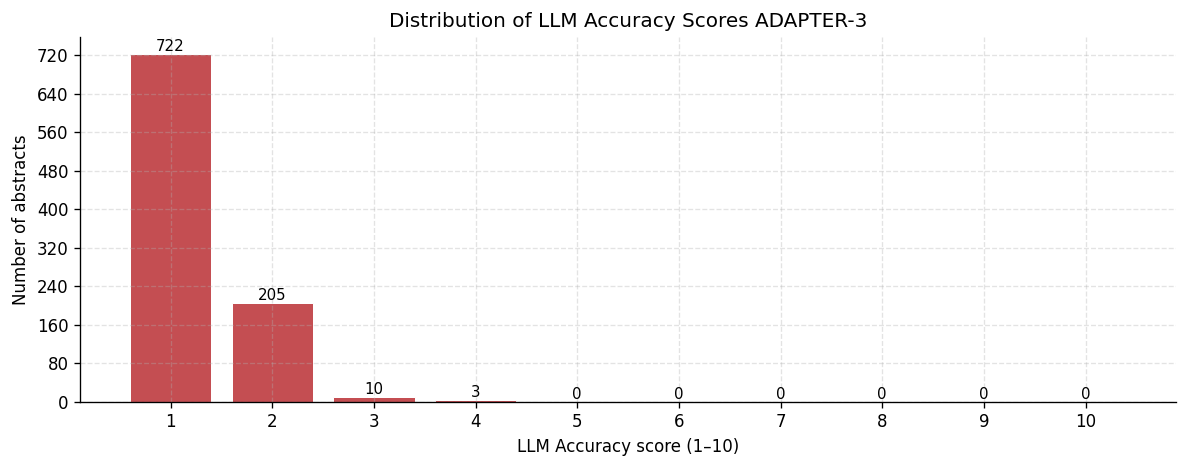

llm_accuracy
1     722
2     205
3      10
4       3
5       0
6       0
7       0
8       0
9       0
10      0
Name: count, dtype: int64

In [6]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_accuracy'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color='#C44E52',
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM Accuracy Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

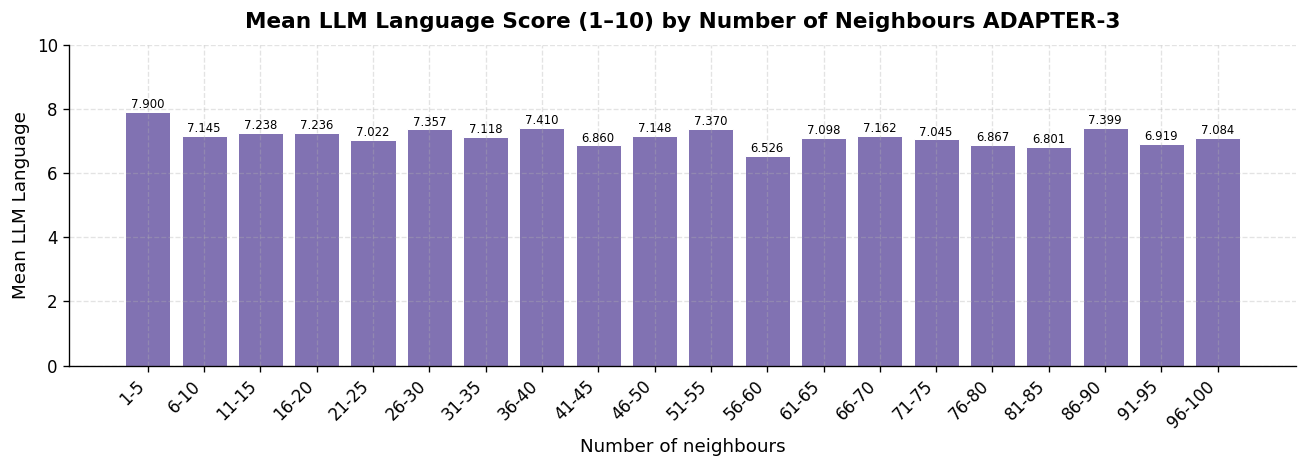

In [7]:
# ── 4. Mean LLM Language ──────────────────────────────────────────────────────
lang_mean = weighted_group_mean(df, 'llm_language')
bar_plot(lang_mean,
         title='Mean LLM Language Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Language',
         color='#8172B2',
         ylim=(0, 10))

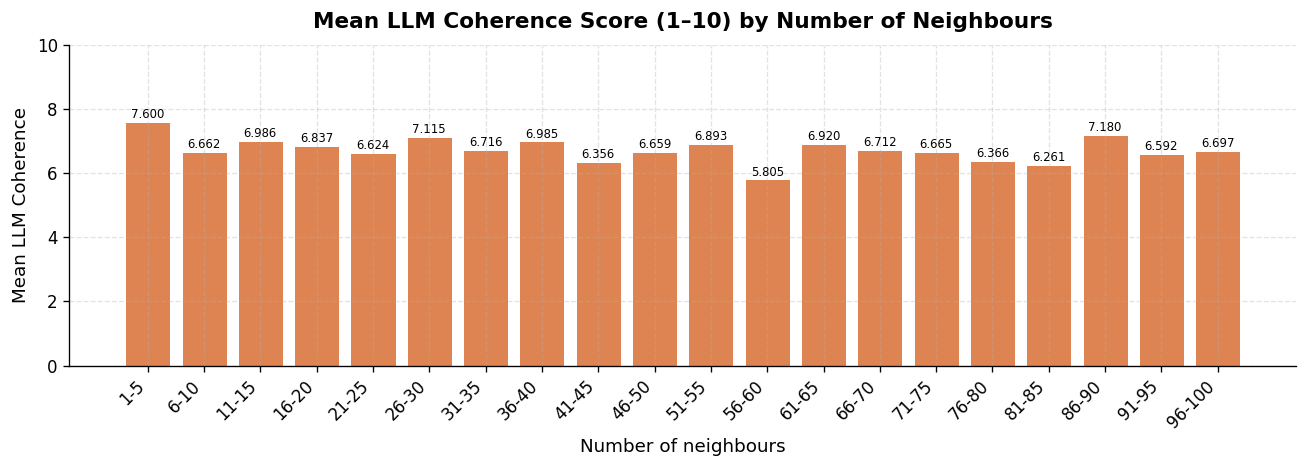

In [8]:
# ── 5. Mean LLM Coherence ─────────────────────────────────────────────────────
coh_mean = weighted_group_mean(df, 'llm_coherence')
bar_plot(coh_mean,
         title='Mean LLM Coherence Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Coherence',
         color='#DD8452',
         ylim=(0, 10))

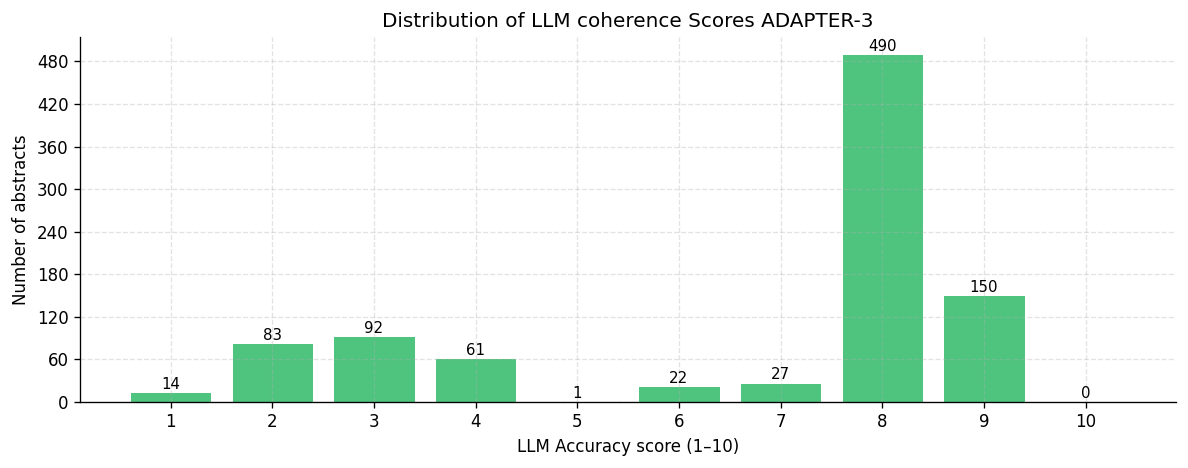

llm_coherence
1      14
2      83
3      92
4      61
5       1
6      22
7      27
8     490
9     150
10      0
Name: count, dtype: int64

In [9]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_coherence'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color="#4EC47F",
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM coherence Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

In [10]:
# ── Mean llm_accuracy excluding low-coherence (1, 2) samples ─────────────────
filtered_df = df[~df['llm_coherence'].isin([1, 2])]

print(f'Excluded {len(df) - len(filtered_df)} rows with llm_coherence in [1, 2]')
print(f'Mean llm_accuracy (all rows):      {df["llm_accuracy"].mean():.4f}')
print(f'Mean llm_accuracy (excluding 1,2): {filtered_df["llm_accuracy"].mean():.4f}')


Excluded 97 rows with llm_coherence in [1, 2]
Mean llm_accuracy (all rows):      1.2489
Mean llm_accuracy (excluding 1,2): 1.2752


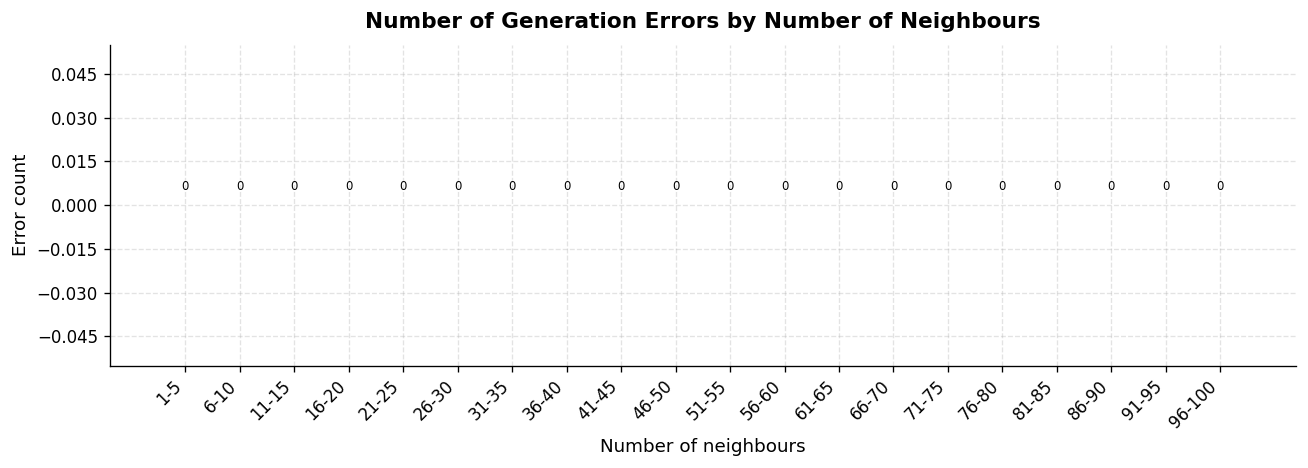

In [11]:
# ── 6. Number of Errors ───────────────────────────────────────────────────────
error_counts = df[df['is_error']].groupby('neighbor_group', observed=True).size().reindex(NEIGHBOR_GROUPS, fill_value=0)
bar_plot(error_counts,
         title='Number of Generation Errors by Number of Neighbours',
         ylabel='Error count',
         color='#CCB974',
         int_yaxis=True)

In [12]:
# ── 5 examples each of llm_coherence score 1 and 2 ───────────────────────────
low_coherence_sample = (
    df[df['llm_coherence'].isin([1, 2])]
    .sort_values('llm_coherence')
    .groupby('llm_coherence', sort=True)
    .apply(lambda g: g.head(5))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_coherence']]
)

pd.set_option('display.max_colwidth', 2000)
low_coherence_sample


/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_97578/3088027966.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(5))


,node_id,original_abstract,generated_abstract,llm_coherence
0,85472,"Non-orthogonal multiple access (NOMA) allows multiple users to share a time-frequency resource block by using different power levels. An important challenge associated with NOMA is the selection of users that share a resource block. This is referred to as clustering, which generally exploits the channel disparity (i.e. distinctness) among the users. We discuss clustering and the related resource allocation challenges (e.g. power allocation) associated with NOMA and highlight open problems that require further investigation. We review the related literature on exploiting channel disparity for clustering and resource allocation. There have been several misconceptions regarding NOMA clustering including: 1) clustering users with low channel disparity is detrimental, 2) similar power allocation is disastrous for NOMA. We clarify such misunderstandings with numerical examples.","In this paper, we consider the problem of distributed source coding with side information at the decoder. We consider the case where the source is a vector of independent and identically distributed (i.i.d.) random variables, and the side information is a vector of i.i.d. random variables that are independent of the source. We consider the case where the side information is available at the decoder, and the source is available at the encoder. We consider the case where the source is available at the encoder, and the side information is available at the decoder. We consider the case where the source is available at the encoder, and the side information is available at the decoder. We consider the case where the source is available at the encoder, and the side information is available at the decoder. We consider the case where the source is available at the encoder, and the side information is available at the decoder. We consider the case where the source is available at the encoder, and the side information is available at the decoder. We consider the case where the source is available at the encoder, and the side information is available at the decoder. We consider the case where the source is available at the encoder, and the side information is available at the decoder. We consider the case where the source is available at the encoder, and the side information is available at the decoder. We consider the case where the source is available at the encoder, and the side information is available at the decoder. We consider the case where the source is available at the encoder, and the side information is available at the decoder. We consider the",1.0
1,118878,"There are abundant cases for using Topological Data Analysis (TDA) in a learning context, but robust topological information commonly comes in the form of a set of persistence diagrams, objects that by nature are uneasy to affix to a generic machine learning framework. We introduce a vectorisation method for diagrams that allows to collect information from topological descriptors into a format fit for machine learning tools. Based on a few observations, the method is learned and tailored to discriminate the various important plane regions a diagram is set into. With this tool one can automatically augment any sort of machine learning problem with access to a TDA method, enhance performances, construct features reflecting underlying changes in topological behaviour. The proposed methodology comes with only high level tuning parameters such as the encoding budget for topological features. We provide an open-access, ready-to-use implementation and notebook. We showcase the strengths and versatility of our approach on a number of applications. From emulous and modern graph collections to a highly topological synthetic dynamical orbits data, we prove that the method matches or beats the state-of-the-art in encoding persistence diagrams to solve hard problems. We then apply our method in the context of an industrial, difficult time-series r

In [13]:
# ── 2 examples per llm_accuracy score ────────────────────────────────────────
sample = (
    df[df['llm_accuracy'].notna()]
    .sort_values('llm_accuracy')
    .groupby('llm_accuracy', sort=True)
    .apply(lambda g: g.head(2))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_accuracy']]
)

pd.set_option('display.max_colwidth', 2000)
sample

/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_97578/263653425.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(2))


,node_id,original_abstract,generated_abstract,llm_accuracy
0,1171,"Fusion of 2D images and 3D point clouds is important because information from dense images can enhance sparse point clouds. However, fusion is challenging because 2D and 3D data live in different spaces. In this work, we propose MVPNet (Multi-View PointNet), where we aggregate 2D multi-view image features into 3D point clouds, and then use a point based network to fuse the features in 3D canonical space to predict 3D semantic labels. To this end, we introduce view selection along with a 2D-3D feature aggregation module. Extensive experiments show the benefit of leveraging features from dense images and reveal superior robustness to varying point cloud density compared to 3D-only methods. On the ScanNetV2 benchmark, our MVPNet significantly outperforms prior point cloud based approaches on the task of 3D Semantic Segmentation. It is much faster to train than the large networks of the sparse voxel approach. We provide solid ablation studies to ease the future design of 2D-3D fusion methods and their extension to other tasks, as we showcase for 3D instance segmentation.",We propose a novel approach to the problem of video summarization. Our approach is based on a deep neural network that is trained to generate a summary of a video by learning to predict the importance of each frame. The network is trained using a novel loss function that is based on the concept of the importance of a frame. We show that our approach outperforms the state-of-the-art methods on the standard benchmark datasets.,1.0
1,104328,"The growing number of low-power smart devices in the Internet of Things is coupled with the concept of ""Edge Computing"", that is moving some of the intelligence, especially machine learning, towards the edge of the network. Enabling machine learning algorithms to run on resource-constrained hardware, typically on low-power smart devices, is challenging in terms of hardware (optimized and energy-efficient integrated circuits), algorithmic and firmware implementations. This paper presents FANN-on-MCU, an open-source toolkit built upon the Fast Artificial Neural Network (FANN) library to run lightweight and energy-efficient neural networks on microcontrollers based on both the ARM Cortex-M series and the novel RISC-V-based Parallel Ultra-Low-Power (PULP) platform. The toolkit takes multi-layer perceptrons trained with FANN and generates code targeted at execution on low-power microcontrollers either with a floating-point unit (i.e., ARM Cortex-M4F and M7F) or without (i.e., ARM Cortex M0-M3 or PULP-based processors). This paper also provides an architectural performance evaluation of neural networks on the most popular ARM Cortex-M family and the parallel RISC-V processor called Mr. Wolf. The evaluation includes experimental results for three different applications using a self-sustainable wearable multi-sensor bracelet. Experimental results show a measured latency in the order of only a few microseconds and a power consumption of few milliwatts while keeping the memory requirements below the limitations of the targeted microcontrollers. In particular, the parallel implementation on the octa-core RISC-V platform reaches a speedup of 22x and a 69% reduction in energy consumption with respect to a single-core implementation on Cortex-M4 for continuous real-time classification.","In this paper, we propose a novel approach to the problem of multi-view clustering. The proposed approach is based on the idea of using the information from multiple views to learn a better clustering structure. We propose a novel multi-view clustering algorithm, which is based on the idea of using the information from multiple views to learn a better clustering structure. We propose a novel multi-view clustering algorithm, which is based on the idea of using the information from multiple views to learn a better clustering structure. We propose a novel multi-view clustering algorithm, which 

In [14]:
# ── Negative category counts ──────────────────────────────────────────────────
NEG_COLS = [
    'cat_wrong_domain', 'cat_multi_paper_contamination', 'cat_wrong_methodology',
    'cat_wrong_task', 'cat_too_generic', 'cat_truncated_incomplete',
]
NEG_LABELS = [
    'Wrong domain', 'Multi-paper contamination', 'Wrong methodology',
    'Wrong task', 'Too generic', 'Truncated / incomplete',
]

neg_counts = df[NEG_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(NEG_LABELS, neg_counts, color='#C44E52', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, neg_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Negative category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()

KeyError: "None of [Index(['cat_wrong_domain', 'cat_multi_paper_contamination',\n       'cat_wrong_methodology', 'cat_wrong_task', 'cat_too_generic',\n       'cat_truncated_incomplete'],\n      dtype='object')] are in the [columns]"

Category definitions:
- wrong_domain: The generated abstract is about a completely different research field or application domain from the original.
- multi_paper_contamination: The text reads like a stitched-together mixture of multiple unrelated papers rather than one coherent abstract.
- wrong_methodology: The domain is broadly correct but describes different techniques or algorithms than the original.
- wrong_task: Same broad field but the specific problem being solved is different (e.g., classification instead of regression, MT instead of summarisation).
- too_generic: Correct domain but described at such a high level of generality that it lacks the specific terminology and framing of the original.
- truncated_incomplete: The abstract ends abruptly mid-sentence or is clearly unfinished.


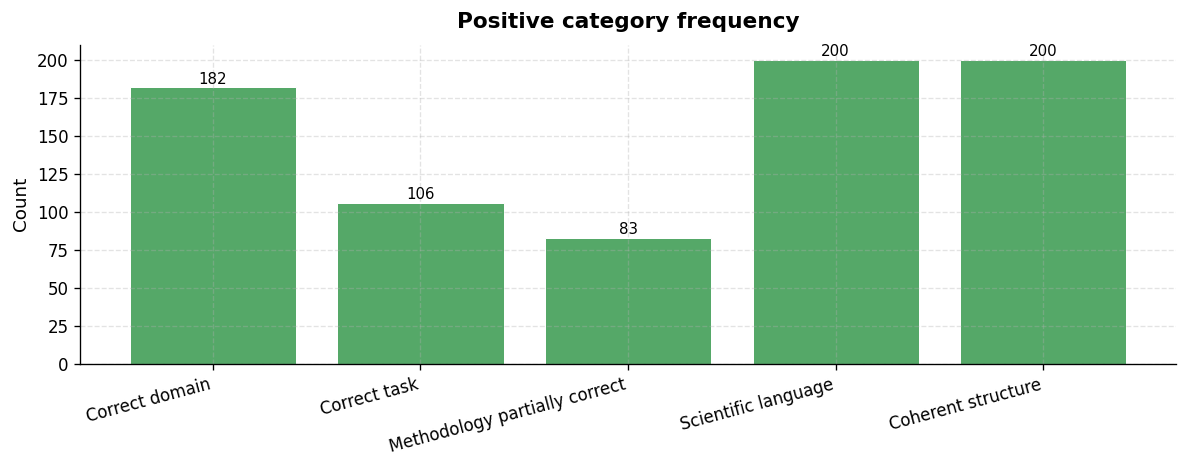

In [ ]:
# ── Positive category counts ──────────────────────────────────────────────────
POS_COLS = [
    'cat_correct_domain', 'cat_correct_task', 'cat_methodology_partially_correct',
    'cat_scientific_language', 'cat_coherent_structure',
]
POS_LABELS = [
    'Correct domain', 'Correct task', 'Methodology partially correct',
    'Scientific language', 'Coherent structure',
]

pos_counts = df[POS_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(POS_LABELS, pos_counts, color='#55A868', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, pos_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Positive category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()